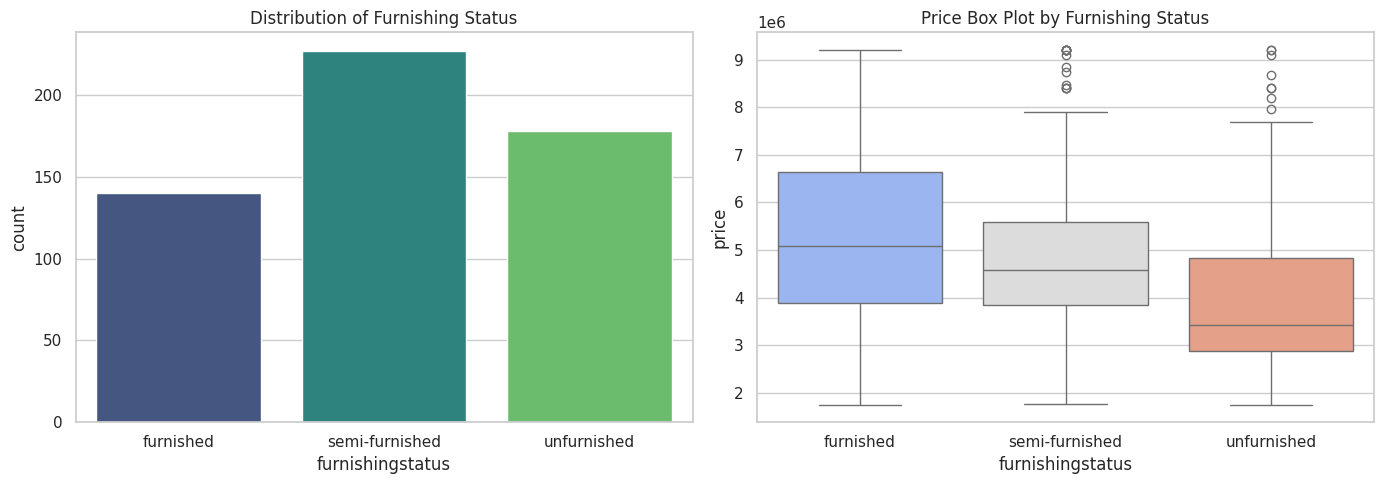

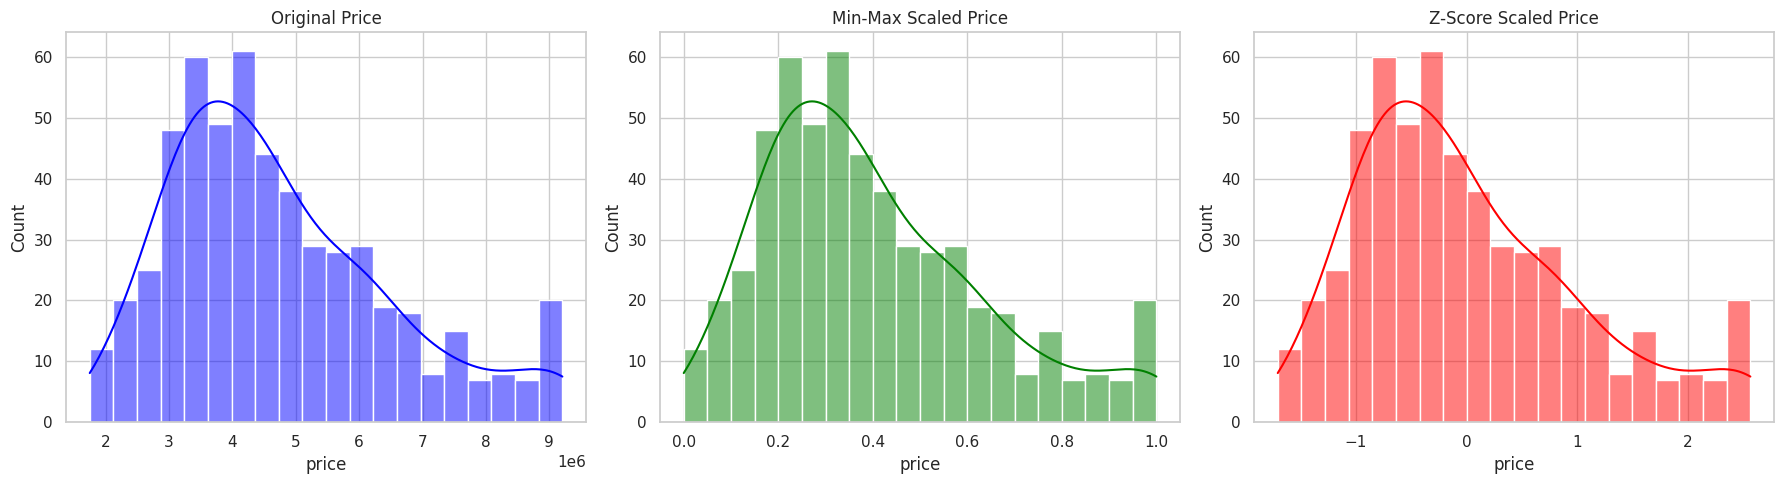

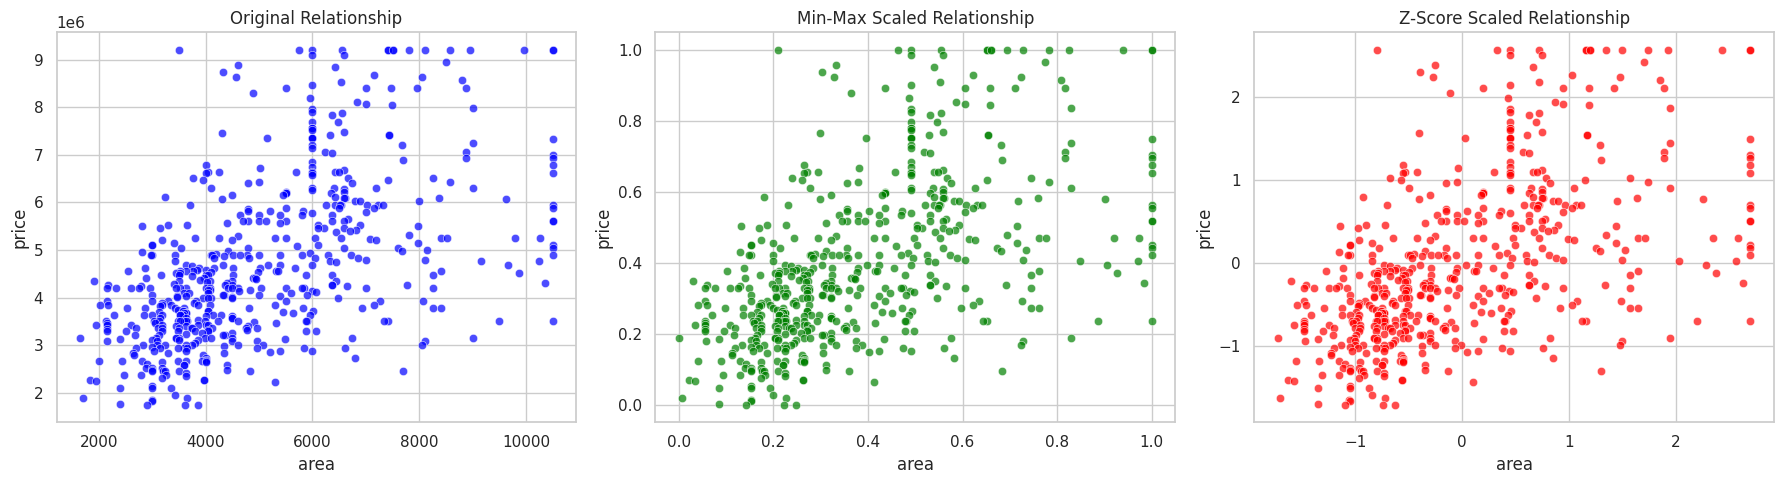

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Load, Clean, Impute & Cap Outliers
df = pd.read_csv('/content/Housing.csv').drop_duplicates().reset_index(drop=True)
for c in df.columns:
    df[c] = df[c].fillna(df[c].median() if df[c].dtype in ['int64', 'float64'] else df[c].mode()[0])
for c in ['price', 'area']:
    q1, q3 = df[c].quantile([0.25, 0.75])
    df[c] = np.clip(df[c], q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1))

# Encode & Scale
df['furnishingstatus_encoded'] = df['furnishingstatus'].map({'unfurnished': 0, 'semi-furnished': 1, 'furnished': 2})
df_enc = pd.get_dummies(df, columns=['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea'], drop_first=True)
feats = ['price', 'area', 'bedrooms', 'bathrooms']

df_mm, df_zs = df_enc.copy(), df_enc.copy()
df_mm[feats] = MinMaxScaler().fit_transform(df_enc[feats])
df_zs[feats] = StandardScaler().fit_transform(df_enc[feats])

# Visualizations
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='furnishingstatus', ax=axes[0], hue='furnishingstatus', palette='viridis', legend=False).set_title('Distribution of Furnishing Status')
sns.boxplot(data=df, x='furnishingstatus', y='price', ax=axes[1], hue='furnishingstatus', palette='coolwarm', legend=False).set_title('Price Box Plot by Furnishing Status')
plt.tight_layout(); plt.show()

for plot_type, name in [('histplot', 'Price'), ('scatterplot', 'Relationship')]:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, data, t, col in zip(axes, [df_enc, df_mm, df_zs], ['Original', 'Min-Max Scaled', 'Z-Score Scaled'], ['blue', 'green', 'red']):
        if plot_type == 'histplot':
            sns.histplot(data['price'], bins=20, kde=True, ax=ax, color=col)
        else:
            sns.scatterplot(data=data, x='area', y='price', ax=ax, color=col, alpha=0.7)
        ax.set_title(f"{t} {name}")
    plt.tight_layout(); plt.show()

In [ ]:
import numpy as np
import pandas as pd

# 1. Load the housing dataset
df_raw = pd.read_csv('/content/Housing.csv')
print(f"Raw dataset shape: {df_raw.shape}")

# 2. Handle duplicates
df_cleaned = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Shape after duplicates removed: {df_cleaned.shape}")

# 3. Handle missing values (Impute numerical with median, categorical with mode)
for col in df_cleaned.columns:
    if df_cleaned[col].dtype in ['int64', 'float64']:
        df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].median())
    else:
        df_cleaned[col] = df_cleaned[col].fillna(df_cleaned[col].mode()[0])

# 4. Handle outliers using the IQR clipping method for continuous features
for col in ['price', 'area']:
    q1, q3 = df_cleaned[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    df_cleaned[col] = np.clip(df_cleaned[col], q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# 5. Encode Ordinal variables (e.g., furnishingstatus)
ordinal_map = {'unfurnished': 0, 'semi-furnished': 1, 'furnished': 2}
df_cleaned['furnishingstatus_encoded'] = df_cleaned['furnishingstatus'].map(ordinal_map)

# 6. Encode Nominal variables (One-hot encoding for binary categorical features)
nominal_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
df_preprocessed = pd.get_dummies(df_cleaned, columns=nominal_cols, drop_first=True)

print(f"Final preprocessed dataset shape: {df_preprocessed.shape}")
print(df_preprocessed.head())

Raw dataset shape: (545, 13)
Shape after duplicates removed: (545, 13)
Final preprocessed dataset shape: (545, 14)
     price  area  bedrooms  bathrooms  stories  parking furnishingstatus  \
0  9205000  7420         4          2        3        2        furnished   
1  9205000  8960         4          4        4        3        furnished   
2  9205000  9960         3          2        2        2   semi-furnished   
3  9205000  7500         4          2        2        3        furnished   
4  9205000  7420         4          1        2        2        furnished   

   furnishingstatus_encoded  mainroad_yes  guestroom_yes  basement_yes  \
0                         2          True          False         False   
1                         2          True          False         False   
2                         1          True          False          True   
3                         2          True          False          True   
4                         2          True           True  

In [ ]:
# @title AI prompt cell

import ipywidgets as widgets
from IPython.display import display, HTML, Markdown,clear_output
from google.colab import ai

dropdown = widgets.Dropdown(
    options=[],
    layout={'width': 'auto'}
)

def update_model_list(new_options):
    dropdown.options = new_options
update_model_list(ai.list_models())

text_input = widgets.Textarea(
    placeholder='Ask me anything....',
    layout={'width': 'auto', 'height': '100px'},
)

button = widgets.Button(
    description='Submit Text',
    disabled=False,
    tooltip='Click to submit the text',
    icon='check'
)

output_area = widgets.Output(
     layout={'width': 'auto', 'max_height': '300px','overflow_y': 'scroll'}
)

def on_button_clicked(b):
    with output_area:
        output_area.clear_output(wait=False)
        accumulated_content = ""
        for new_chunk in ai.generate_text(prompt=text_input.value, model_name=dropdown.value, stream=True):
            if new_chunk is None:
                continue
            accumulated_content += new_chunk
            clear_output(wait=True)
            display(Markdown(accumulated_content))

button.on_click(on_button_clicked)
vbox = widgets.GridBox([dropdown, text_input, button, output_area])

display(HTML("""
<style>
.widget-dropdown select {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
.widget-textarea textarea {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
</style>
"""))
display(vbox)


GridBox(children=(Dropdown(layout=Layout(width='auto'), options=('google/gemini-3.5-flash-lite', 'google/gemin…

--- Dataset Comparison ---
    Original_Data  MinMax_Normalized  ZScore_Standardized
0             120           0.000000            -0.754593
1             150           0.027778            -0.651267
2             170           0.046296            -0.582383
3             200           0.074074            -0.479057
4             220           0.092593            -0.410173
5             250           0.120370            -0.306847
6             270           0.138889            -0.237963
7             300           0.166667            -0.134637
8             350           0.212963             0.037573
9             500           0.351852             0.554203
10           1200           1.000000             2.965143


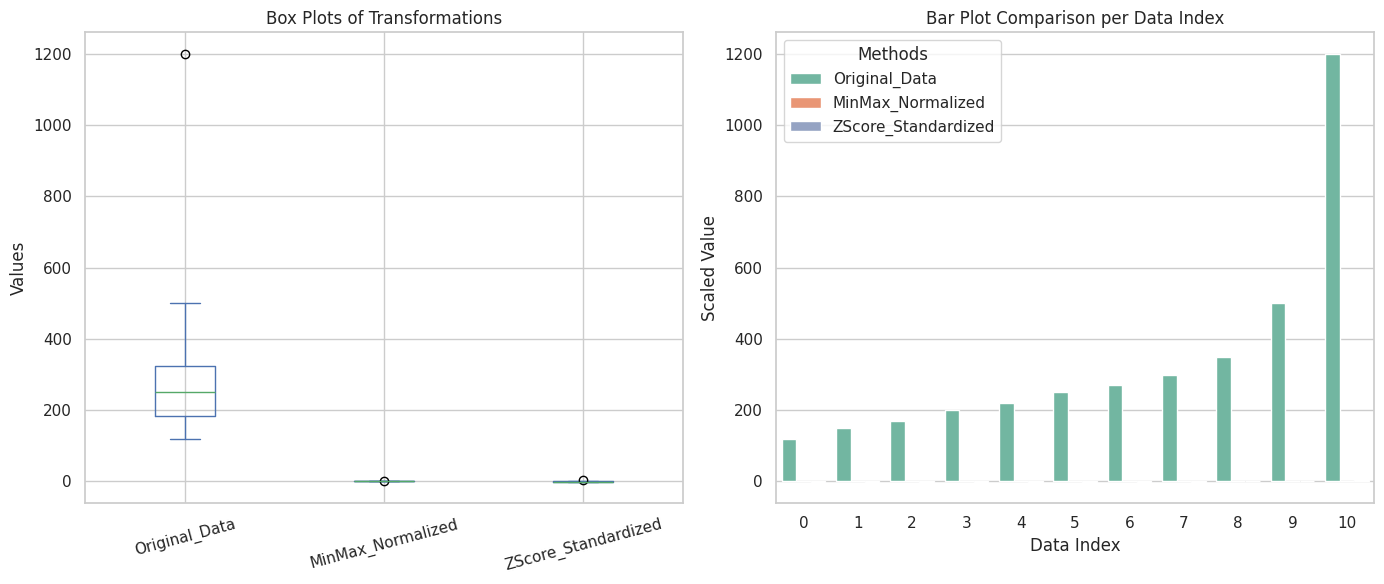

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Create a sample dataset
# Let's assume we have a feature representing "House Prices (in thousands)"
np.random.seed(42)
data = {
    "Original_Data": [
        120,
        150,
        170,
        200,
        220,
        250,
        270,
        300,
        350,
        500,
        1200,
    ]  # Includes an outlier (1200)
}
df = pd.DataFrame(data)

# 2. Apply Min-Max Normalization (Scaling to range [0, 1])
min_max_scaler = MinMaxScaler()
df["MinMax_Normalized"] = min_max_scaler.fit_transform(df[["Original_Data"]])

# 3. Apply Z-Score Standardization (Mean = 0, Standard Deviation = 1)
z_score_scaler = StandardScaler()
df["ZScore_Standardized"] = z_score_scaler.fit_transform(df[["Original_Data"]])

# Display the dataframe with transformed values
print("--- Dataset Comparison ---")
print(df)

# ==========================================
# 4. GENERATE PLOTS
# ==========================================

# Set the visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- BOX PLOTS ---
# Box plots are great for showing the distribution, median, and outliers
df.plot(kind="box", ax=axes[0])
axes[0].set_title("Box Plots of Transformations")
axes[0].set_ylabel("Values")
axes[0].tick_params(axis="x", rotation=15)

# --- BAR PLOTS (Comparison of individual data points) ---
# Reshape dataframe for a grouped bar plot using Seaborn
df_melted = pd.melt(
    df,
    var_name="Transformation_Type",
    value_name="Value",
    ignore_index=False,
).reset_index()

sns.barplot(
    x="index",
    y="Value",
    hue="Transformation_Type",
    data=df_melted,
    ax=axes[1],
    palette="Set2",
)
axes[1].set_title("Bar Plot Comparison per Data Index")
axes[1].set_xlabel("Data Index")
axes[1].set_ylabel("Scaled Value")
axes[1].legend(title="Methods")

# Adjust layout and show plots
plt.tight_layout()
plt.show()

In [ ]:
# @title AI prompt cell

import ipywidgets as widgets
from IPython.display import display, HTML, Markdown,clear_output
from google.colab import ai

dropdown = widgets.Dropdown(
    options=[],
    layout={'width': 'auto'}
)

def update_model_list(new_options):
    dropdown.options = new_options
update_model_list(ai.list_models())

text_input = widgets.Textarea(
    placeholder='Ask me anything....',
    layout={'width': 'auto', 'height': '100px'},
)

button = widgets.Button(
    description='Submit Text',
    disabled=False,
    tooltip='Click to submit the text',
    icon='check'
)

output_area = widgets.Output(
     layout={'width': 'auto', 'max_height': '300px','overflow_y': 'scroll'}
)

def on_button_clicked(b):
    with output_area:
        output_area.clear_output(wait=False)
        accumulated_content = ""
        for new_chunk in ai.generate_text(prompt=text_input.value, model_name=dropdown.value, stream=True):
            if new_chunk is None:
                continue
            accumulated_content += new_chunk
            clear_output(wait=True)
            display(Markdown(accumulated_content))

button.on_click(on_button_clicked)
vbox = widgets.GridBox([dropdown, text_input, button, output_area])

display(HTML("""
<style>
.widget-dropdown select {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
.widget-textarea textarea {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
</style>
"""))
display(vbox)


GridBox(children=(Dropdown(layout=Layout(width='auto'), options=('google/gemini-3.5-flash-lite', 'google/gemin…

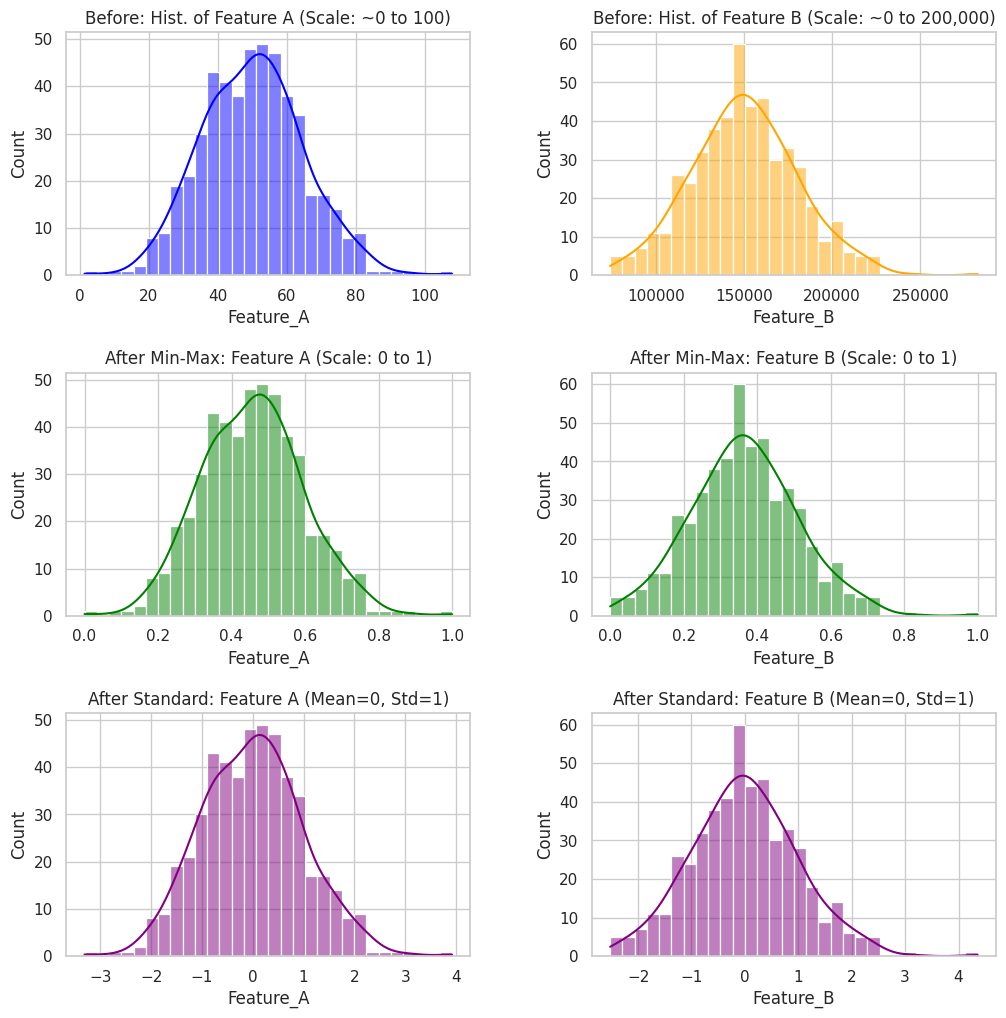

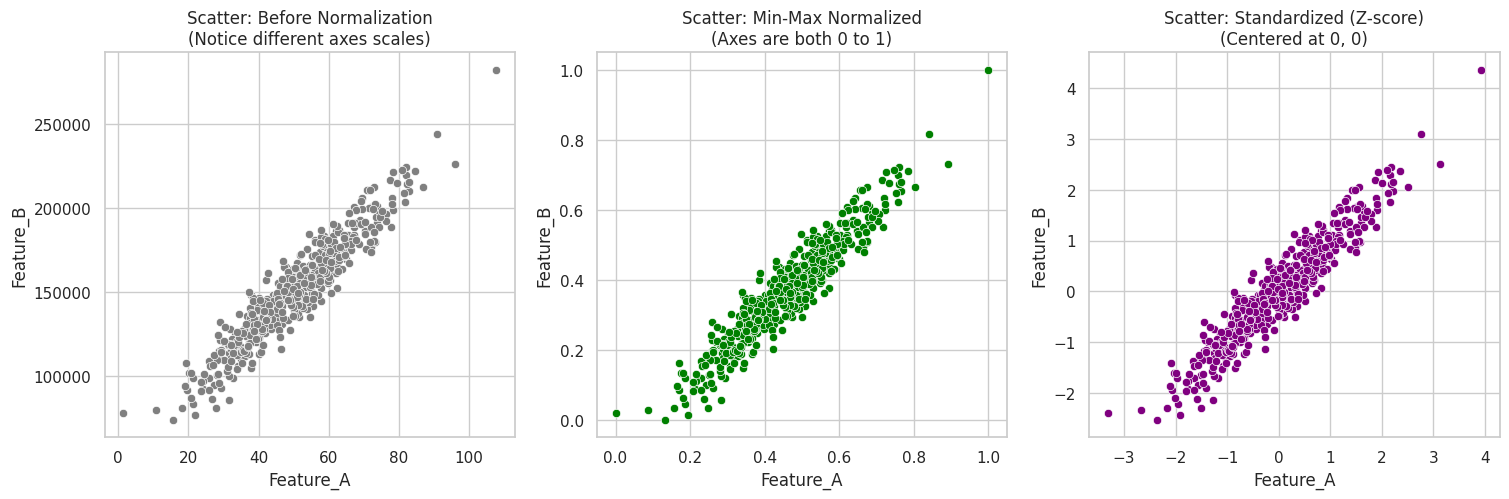

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Generate Synthetic Data with different scales and a clear relationship
np.random.seed(42)
n_samples = 500

# Feature A: Mean = 50, Std = 15 (e.g., Age or Weight)
feature_a = np.random.normal(loc=50, scale=15, size=n_samples)

# Feature B: Mean = 100000, Std = 25000 (e.g., Salary)
# Let's create a positive linear relationship with Feature A plus some noise
feature_b = (
    feature_a * 2000 + np.random.normal(loc=0, scale=10000, size=n_samples)
) + 50000

df = pd.DataFrame({'Feature_A': feature_a, 'Feature_B': feature_b})

# 2. Apply Normalization/Scaling
# Min-Max Scaling (Scales data between 0 and 1)
min_max_scaler = MinMaxScaler()
df_minmax = pd.DataFrame(
    min_max_scaler.fit_transform(df), columns=['Feature_A', 'Feature_B']
)

# Standard Scaling (Z-score: Mean = 0, Std = 1)
std_scaler = StandardScaler()
df_std = pd.DataFrame(
    std_scaler.fit_transform(df), columns=['Feature_A', 'Feature_B']
)

# 3. Plotting
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

# --- BEFORE NORMALIZATION ---
sns.histplot(
    df['Feature_A'], ax=axes[0, 0], color='blue', kde=True, bins=30
)
axes[0, 0].set_title('Before: Hist. of Feature A (Scale: ~0 to 100)')

sns.histplot(
    df['Feature_B'], ax=axes[0, 1], color='orange', kde=True, bins=30
)
axes[0, 1].set_title('Before: Hist. of Feature B (Scale: ~0 to 200,000)')

# We will use a scatter plot function to show relationships
# To show both features on a scatter plot effectively before/after, we plot A vs B
# (Note: For raw data, A vs B on the same axes looks weird due to scale, so we use standardized for comparison)

# --- AFTER MIN-MAX NORMALIZATION ---
sns.histplot(
    df_minmax['Feature_A'], ax=axes[1, 0], color='green', kde=True, bins=30
)
axes[1, 0].set_title('After Min-Max: Feature A (Scale: 0 to 1)')
sns.histplot(
    df_minmax['Feature_B'], ax=axes[1, 1], color='green', kde=True, bins=30
)
axes[1, 1].set_title('After Min-Max: Feature B (Scale: 0 to 1)')

# --- AFTER STANDARD SCALER (Z-SCORE) ---
sns.histplot(
    df_std['Feature_A'], ax=axes[2, 0], color='purple', kde=True, bins=30
)
axes[2, 0].set_title('After Standard: Feature A (Mean=0, Std=1)')
sns.histplot(
    df_std['Feature_B'], ax=axes[2, 1], color='purple', kde=True, bins=30
)
axes[2, 1].set_title('After Standard: Feature B (Mean=0, Std=1)')

plt.show()

# --- SCATTER PLOT COMPARISON ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=df, x='Feature_A', y='Feature_B', ax=axes[0], color='gray'
)
axes[0].set_title('Scatter: Before Normalization\n(Notice different axes scales)')

sns.scatterplot(
    data=df_minmax, x='Feature_A', y='Feature_B', ax=axes[1], color='green'
)
axes[1].set_title('Scatter: Min-Max Normalized\n(Axes are both 0 to 1)')

sns.scatterplot(
    data=df_std, x='Feature_A', y='Feature_B', ax=axes[2], color='purple'
)
axes[2].set_title('Scatter: Standardized (Z-score)\n(Centered at 0, 0)')

plt.show()

In [ ]:
# @title AI prompt cell

import ipywidgets as widgets
from IPython.display import display, HTML, Markdown,clear_output
from google.colab import ai

dropdown = widgets.Dropdown(
    options=[],
    layout={'width': 'auto'}
)

def update_model_list(new_options):
    dropdown.options = new_options
update_model_list(ai.list_models())

text_input = widgets.Textarea(
    placeholder='Ask me anything....',
    layout={'width': 'auto', 'height': '100px'},
)

button = widgets.Button(
    description='Submit Text',
    disabled=False,
    tooltip='Click to submit the text',
    icon='check'
)

output_area = widgets.Output(
     layout={'width': 'auto', 'max_height': '300px','overflow_y': 'scroll'}
)

def on_button_clicked(b):
    with output_area:
        output_area.clear_output(wait=False)
        accumulated_content = ""
        for new_chunk in ai.generate_text(prompt=text_input.value, model_name=dropdown.value, stream=True):
            if new_chunk is None:
                continue
            accumulated_content += new_chunk
            clear_output(wait=True)
            display(Markdown(accumulated_content))

button.on_click(on_button_clicked)
vbox = widgets.GridBox([dropdown, text_input, button, output_area])

display(HTML("""
<style>
.widget-dropdown select {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
.widget-textarea textarea {
    font-size: 18px;
    font-family: "Arial", sans-serif;
}
</style>
"""))
display(vbox)


GridBox(children=(Dropdown(layout=Layout(width='auto'), options=('google/gemini-3.5-flash-lite', 'google/gemin…

Original Dataset Shape (with duplicates & nulls): (1025, 6)
Removed 25 duplicate rows.
Missing values and outliers handled successfully.


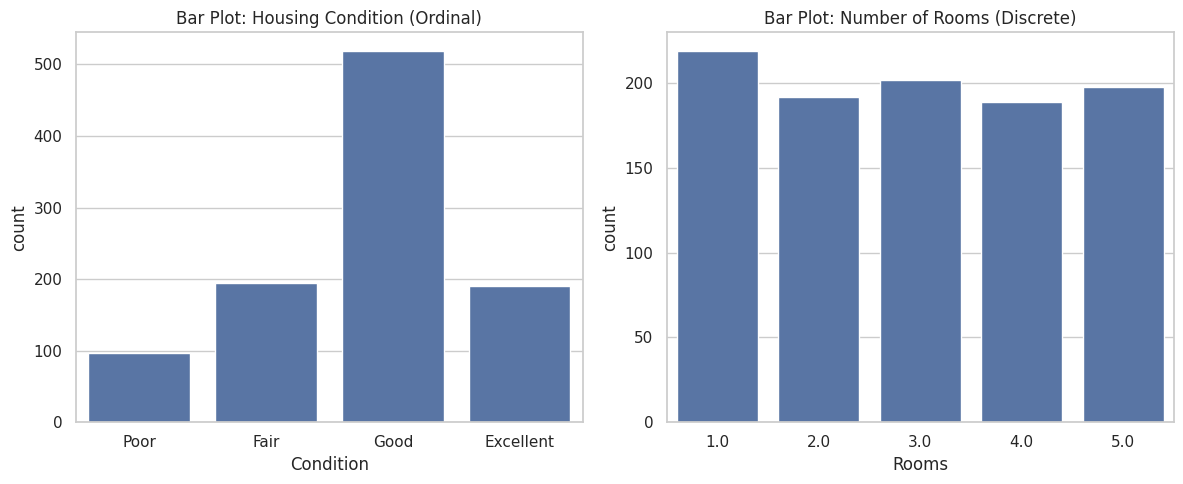

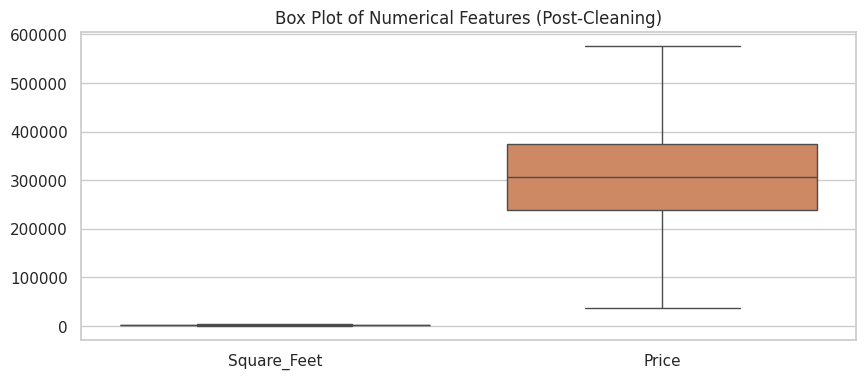

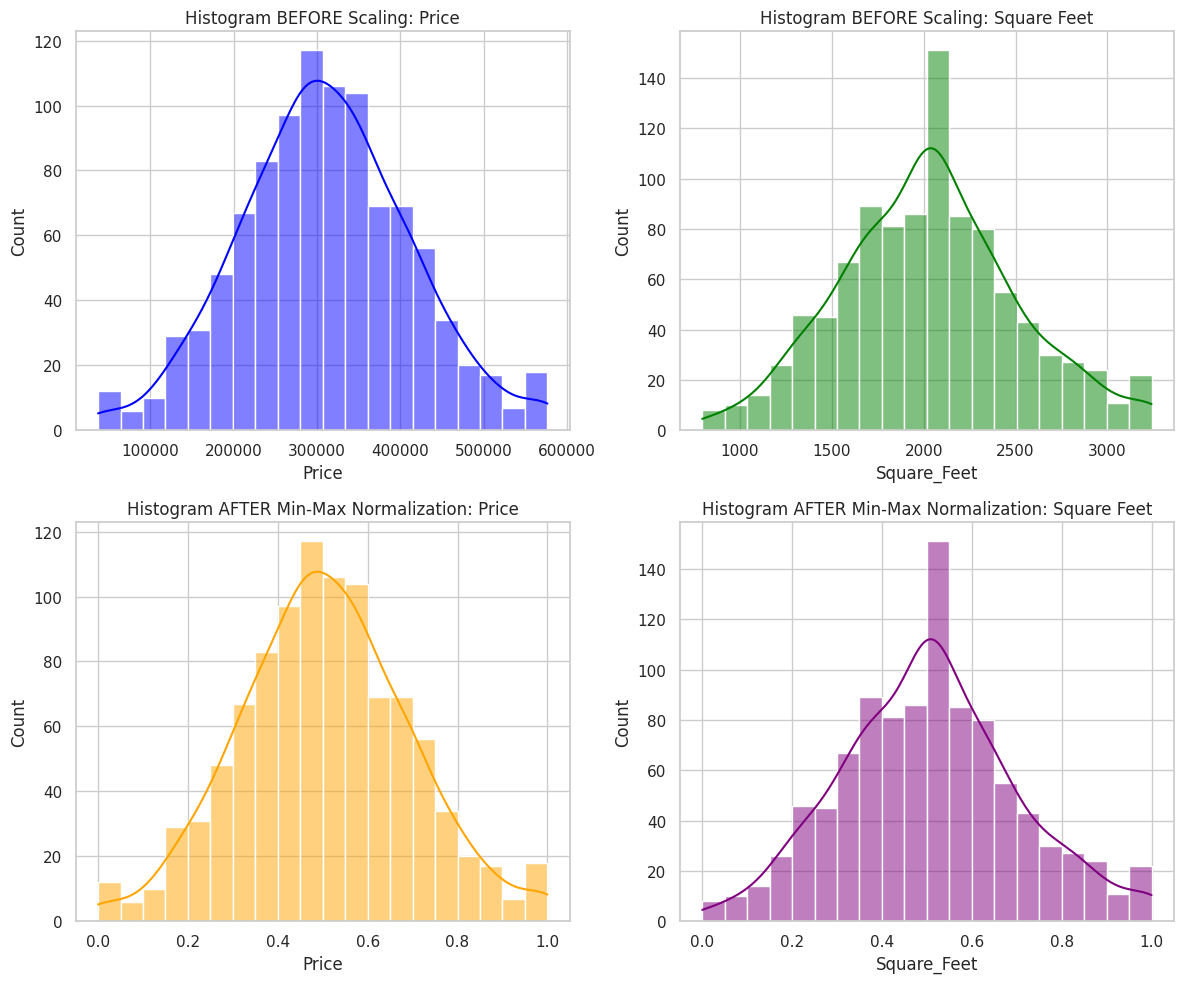

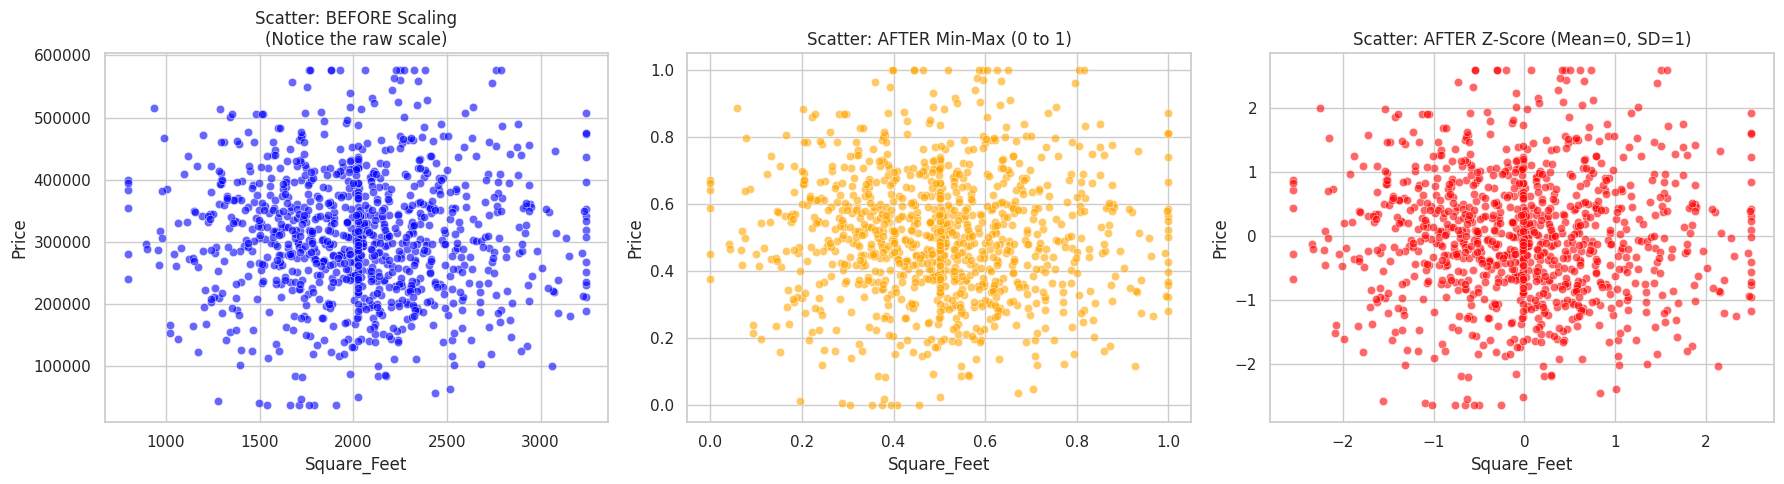

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Set random seed for reproducibility
np.random.seed(42)

# ==========================================
# 1. CREATE SYNTHETIC HOUSING DATASET
# ==========================================
n_samples = 1000

data = {
    # Continuous / Numerical with outliers and missing values
    "Square_Feet": np.random.normal(2000, 500, n_samples),
    "Price": np.random.normal(300000, 100000, n_samples),
    # Discrete
    "Rooms": np.random.randint(1, 6, n_samples),
    "Bathrooms": np.random.randint(1, 4, n_samples),
    # Ordinal (Categorical with logical order)
    "Condition": np.random.choice(
        ["Poor", "Fair", "Good", "Excellent"],
        n_samples,
        p=[0.1, 0.2, 0.5, 0.2],
    ),
    # Nominal (Categorical without logical order)
    "Neighborhood": np.random.choice(
        ["Suburban", "Urban", "Rural"], n_samples, p=[0.4, 0.4, 0.2]
    ),
}

df = pd.DataFrame(data)

# Introduce Outliers
df.loc[0:10, "Price"] = df["Price"] * 5  # Extreme high prices
df.loc[11:20, "Square_Feet"] = df["Square_Feet"] * 4

# Introduce Missing Values (NaNs)
df.loc[np.random.choice(n_samples, 50), "Square_Feet"] = np.nan
df.loc[np.random.choice(n_samples, 30), "Condition"] = np.nan

# Introduce Duplicates
df = pd.concat([df, df.iloc[0:25]], ignore_index=True)

print(f"Original Dataset Shape (with duplicates & nulls): {df.shape}")

# ==========================================
# 2. DATA CLEANING
# ==========================================

# A. Handle Duplicates
initial_rows = len(df)
df = df.drop_duplicates()
print(f"Removed {initial_rows - len(df)} duplicate rows.")

# B. Handle Missing Values
# Numerical: Impute with Median
num_cols = ["Square_Feet", "Price", "Rooms", "Bathrooms"]
num_imputer = SimpleImputer(strategy="median")
df[num_cols] = num_imputer.fit_transform(df[num_cols])

# Categorical (Ordinal/Nominal): Impute with Most Frequent (Mode)
cat_cols = ["Condition", "Neighborhood"]
cat_imputer = SimpleImputer(strategy="most_frequent")
df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])

# C. Handle Outliers (Using IQR method on continuous variables)
for col in ["Square_Feet", "Price"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Cap the outliers (Winsorization) instead of dropping
    df[col] = np.clip(df[col], lower_bound, upper_bound)

print("Missing values and outliers handled successfully.")

# ==========================================
# 3. ENCODING CATEGORICAL VARIABLES
# ==========================================
# Ordinal Encoding
condition_mapping = {"Poor": 1, "Fair": 2, "Good": 3, "Excellent": 4}
df["Condition_Encoded"] = df["Condition"].map(condition_mapping)

# Nominal Encoding (One-Hot Encoding)
df = pd.get_dummies(df, columns=["Neighborhood"], drop_first=True, dtype=int)


# ==========================================
# 4. FEATURE SCALING (Min-Max & Z-Score)
# ==========================================
features_to_scale = ["Square_Feet", "Price"]

# Copy for scaling
df_minmax = df.copy()
df_zscore = df.copy()

# Min-Max Normalization (Scales between 0 and 1)
min_max_scaler = MinMaxScaler()
df_minmax[features_to_scale] = min_max_scaler.fit_transform(
    df[features_to_scale]
)

# Z-Score Standardization (Mean = 0, Standard Deviation = 1)
z_scaler = StandardScaler()
df_zscore[features_to_scale] = z_scaler.fit_transform(df[features_to_scale])


# ==========================================
# 5. EXPLORATORY DATA VISUALIZATION
# ==========================================
sns.set_theme(style="whitegrid")

# --- A. Bar Plots (for Categorical/Discrete variables) ---
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x="Condition", order=["Poor", "Fair", "Good", "Excellent"])
plt.title("Bar Plot: Housing Condition (Ordinal)")

plt.subplot(1, 2, 2)
sns.countplot(data=df, x="Rooms")
plt.title("Bar Plot: Number of Rooms (Discrete)")
plt.tight_layout()
plt.show()

# --- B. Box Plots (to visualize distributions and remaining outliers) ---
plt.figure(figsize=(10, 4))
sns.boxplot(data=df[["Square_Feet", "Price"]])
plt.title("Box Plot of Numerical Features (Post-Cleaning)")
plt.show()

# --- C. Histograms: BEFORE vs AFTER Normalization ---
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Before
sns.histplot(df["Price"], kde=True, ax=axes[0, 0], color="blue")
axes[0, 0].set_title("Histogram BEFORE Scaling: Price")

sns.histplot(df["Square_Feet"], kde=True, ax=axes[0, 1], color="green")
axes[0, 1].set_title("Histogram BEFORE Scaling: Square Feet")

# After Min-Max
sns.histplot(df_minmax["Price"], kde=True, ax=axes[1, 0], color="orange")
axes[1, 0].set_title("Histogram AFTER Min-Max Normalization: Price")

sns.histplot(df_minmax["Square_Feet"], kde=True, ax=axes[1, 1], color="purple")
axes[1, 1].set_title("Histogram AFTER Min-Max Normalization: Square Feet")

plt.tight_layout()
plt.show()

# --- D. Scatter Plots: BEFORE vs AFTER Standardization ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Before
sns.scatterplot(
    data=df, x="Square_Feet", y="Price", ax=axes[0], alpha=0.6, color="blue"
)
axes[0].set_title("Scatter: BEFORE Scaling\n(Notice the raw scale)")

# Min-Max Scaled
sns.scatterplot(
    data=df_minmax,
    x="Square_Feet",
    y="Price",
    ax=axes[1],
    alpha=0.6,
    color="orange",
)
axes[1].set_title("Scatter: AFTER Min-Max (0 to 1)")

# Z-Score Standardized
sns.scatterplot(
    data=df_zscore,
    x="Square_Feet",
    y="Price",
    ax=axes[2],
    alpha=0.6,
    color="red",
)
axes[2].set_title("Scatter: AFTER Z-Score (Mean=0, SD=1)")

plt.tight_layout()
plt.show()